In [3]:
import numpy as np
import pandas as pd


In [4]:
df = pd.read_csv("winequality-white.csv", sep=";")

In [5]:
df.shape

(4898, 12)

In [6]:
df

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.00100,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.99400,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.99510,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6
...,...,...,...,...,...,...,...,...,...,...,...,...
4893,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6
4894,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5
4895,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6
4896,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB


In [8]:
df["quality"].value_counts().sort_index()

quality
3      20
4     163
5    1457
6    2198
7     880
8     175
9       5
Name: count, dtype: int64

In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,4898.0,6.854788,0.843868,3.80000,6.300000,6.80000,7.3000,14.20000
volatile acidity,4898.0,0.278241,0.100795,0.08000,0.210000,0.26000,0.3200,1.10000
citric acid,4898.0,0.334192,0.121020,0.00000,0.270000,0.32000,0.3900,1.66000
residual sugar,4898.0,6.391415,5.072058,0.60000,1.700000,5.20000,9.9000,65.80000
chlorides,4898.0,0.045772,0.021848,0.00900,0.036000,0.04300,0.0500,0.34600
free sulfur dioxide,4898.0,35.308085,17.007137,2.00000,23.000000,34.00000,46.0000,289.00000
total sulfur dioxide,4898.0,138.360657,42.498065,9.00000,108.000000,134.00000,167.0000,440.00000
density,4898.0,0.994027,0.002991,0.98711,0.991723,0.99374,0.9961,1.03898
pH,4898.0,3.188267,0.151001,2.72000,3.090000,3.18000,3.2800,3.82000
sulphates,4898.0,0.489847,0.114126,0.22000,0.410000,0.47000,0.5500,1.08000


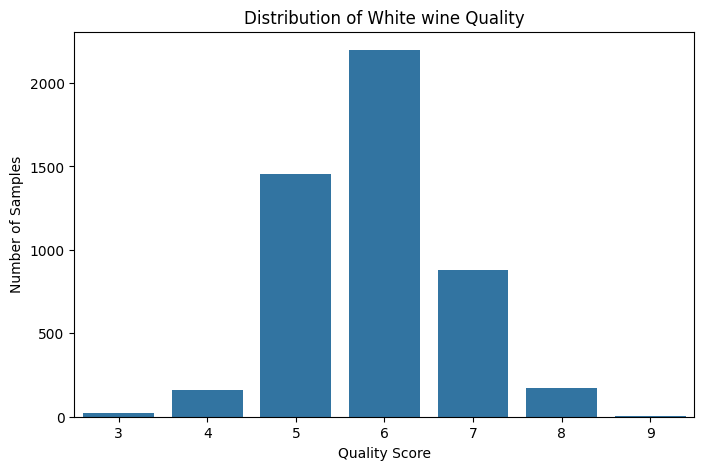

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.countplot(data=df, x="quality")
plt.title("Distribution of White wine Quality")
plt.xlabel("Quality Score")
plt.ylabel("Number of Samples")
plt.show()

Text(0.5, 1.0, 'Correlation Matrix of White Wine Features')

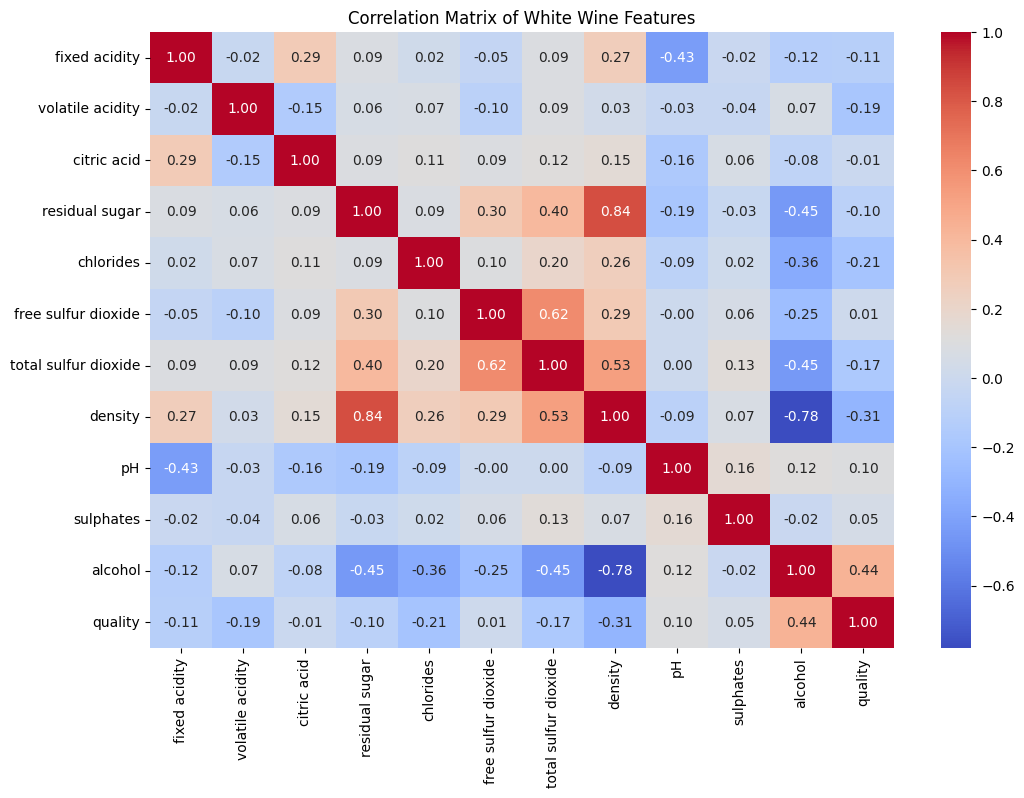

In [11]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(),annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation Matrix of White Wine Features")

array([[<Axes: title={'center': 'fixed acidity'}>,
        <Axes: title={'center': 'volatile acidity'}>,
        <Axes: title={'center': 'citric acid'}>],
       [<Axes: title={'center': 'residual sugar'}>,
        <Axes: title={'center': 'chlorides'}>,
        <Axes: title={'center': 'free sulfur dioxide'}>],
       [<Axes: title={'center': 'total sulfur dioxide'}>,
        <Axes: title={'center': 'density'}>,
        <Axes: title={'center': 'pH'}>],
       [<Axes: title={'center': 'sulphates'}>,
        <Axes: title={'center': 'alcohol'}>, <Axes: >]], dtype=object)

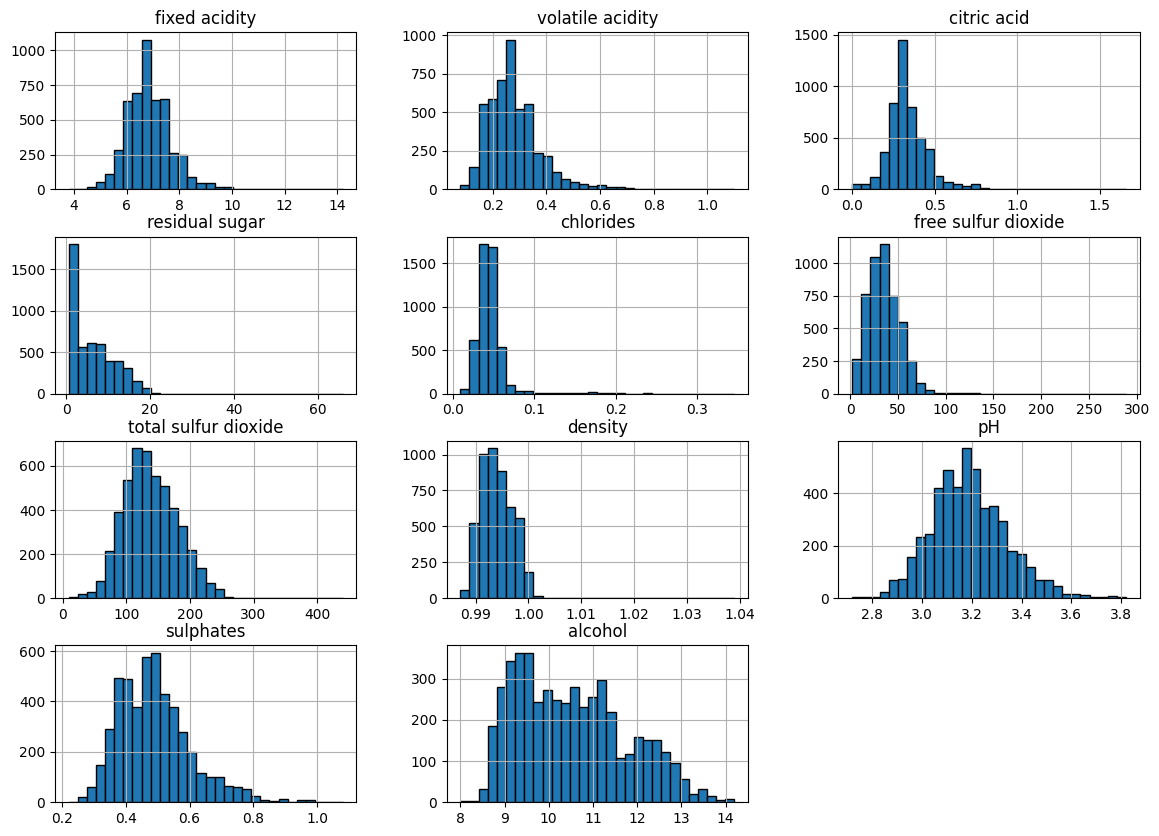

In [12]:
df.drop(columns="quality").hist(figsize=(14,10),bins=30,edgecolor="black")

In [13]:
plt.suptitle("Distribution of White Wine Features")
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

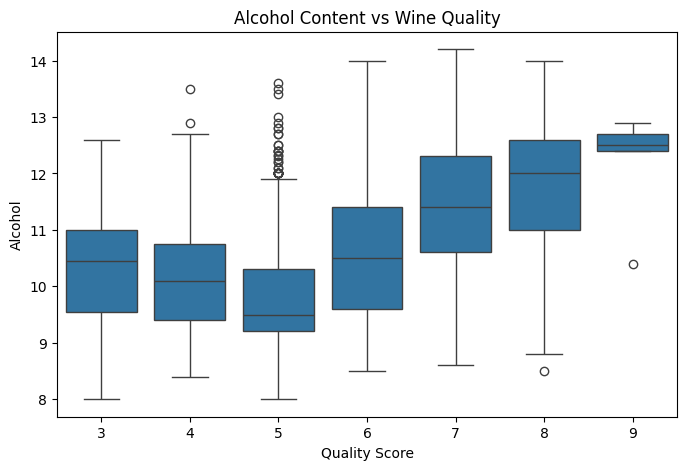

In [14]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="quality", y="alcohol")

plt.title("Alcohol Content vs Wine Quality")
plt.xlabel("Quality Score")
plt.ylabel("Alcohol")
plt.show()

In [15]:
X= df.drop(columns=["quality"])
y= df["quality"]


In [16]:
X.shape

(4898, 11)

In [17]:
y.shape

(4898,)

In [18]:
from sklearn.model_selection import train_test_split

X=df.drop(columns=["quality"])
y=df["quality"]
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)


In [19]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(3918, 11)
(980, 11)
(3918,)
(980,)


In [20]:
from sklearn.ensemble import RandomForestRegressor
model = RandomForestRegressor(n_estimators=300,random_state=42,n_jobs=-1)
model.fit(X_train,y_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [21]:
y_pred = model.predict(X_test)

In [22]:
results = pd.DataFrame({
    "Actual":y_test.values,
    "predicted":y_pred.round(4)
})

In [23]:
results.head(10)

,Actual,predicted
0,7,6.8567
1,8,7.5933
2,8,6.6600
3,5,5.1833
4,7,6.8400
5,6,6.2500
6,5,5.2633
7,4,5.2200
8,6,5.8600
9,5,5.1733


In [24]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

MAE:  0.4167
RMSE: 0.5876
R²:   0.5542


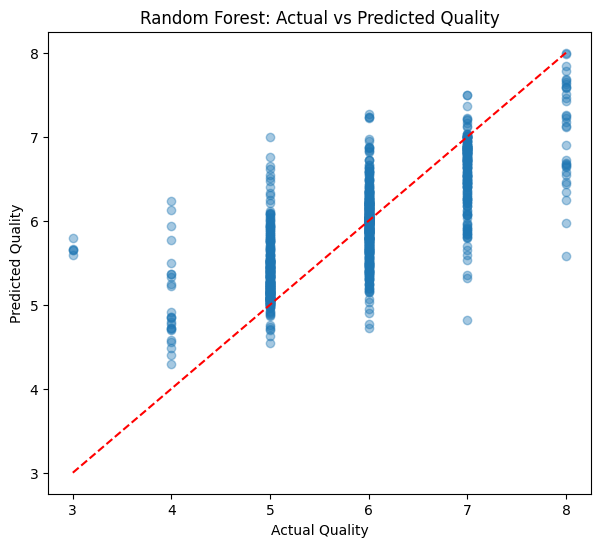

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, alpha=0.4)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual Quality")
plt.ylabel("Predicted Quality")
plt.title("Random Forest: Actual vs Predicted Quality")
plt.show()

In [26]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

print("Baseline MAE:", round(mean_absolute_error(y_test, baseline_pred), 4))
print("Baseline RMSE:", round(mean_squared_error(y_test, baseline_pred) ** 0.5, 4))
print("Baseline R²:", round(r2_score(y_test, baseline_pred), 4))

Baseline MAE: 0.675
Baseline RMSE: 0.8806
Baseline R²: -0.0014


In [27]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd

results = []

for n in [100, 200, 300, 500]:
    model = RandomForestRegressor(
        n_estimators=n,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    results.append({
        "Trees": n,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": mean_squared_error(y_test, pred) ** 0.5,
        "R2": r2_score(y_test, pred)
    })

pd.DataFrame(results).round(4)

,Trees,MAE,RMSE,R2
0,100,0.4185,0.5897,0.5510
1,200,0.4172,0.5877,0.5541
2,300,0.4167,0.5876,0.5542
3,500,0.4164,0.5861,0.5564


In [28]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Settings we want to experiment with
param_grid = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 10, 15, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [0.7, 1.0]
}

# Our basic Random Forest
rf = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

# Automatically test 25 randomly selected configurations
search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=25,
    scoring="neg_mean_absolute_error",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print("Best CV MAE:", -search.best_score_)

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best parameters: {'n_estimators': 500, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.7, 'max_depth': 30}
Best CV MAE: 0.46080356882334994


In [29]:
best_model = search.best_estimator_
tuned_pred = best_model.predict(X_test)

print("Test MAE:", mean_absolute_error(y_test, tuned_pred))
print("Test RMSE:", mean_squared_error(y_test, tuned_pred) ** 0.5)
print("Test R²:", r2_score(y_test, tuned_pred))

Test MAE: 0.42640632088909286
Test RMSE: 0.5881828603440057
Test R²: 0.5532975115148093


## Red Wine Dataset

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

red_df = pd.read_csv("winequality-red.csv", sep=";")

print("Dataset shape:", red_df.shape)
red_df.head()

Dataset shape: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [31]:
red_df.info()

print("\nMissing values:")
print(red_df.isnull().sum())

print("\nQuality distribution:")
print(red_df["quality"].value_counts().sort_index())

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

Missing values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides       

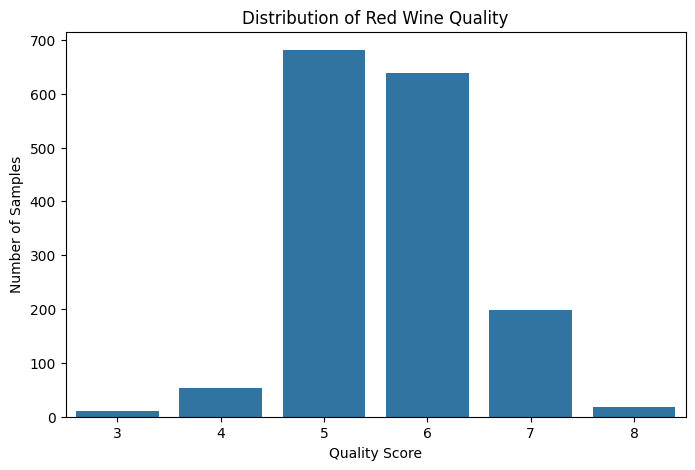

In [32]:
plt.figure(figsize=(8, 5))

sns.countplot(data=red_df, x="quality")

plt.title("Distribution of Red Wine Quality")
plt.xlabel("Quality Score")
plt.ylabel("Number of Samples")
plt.show()

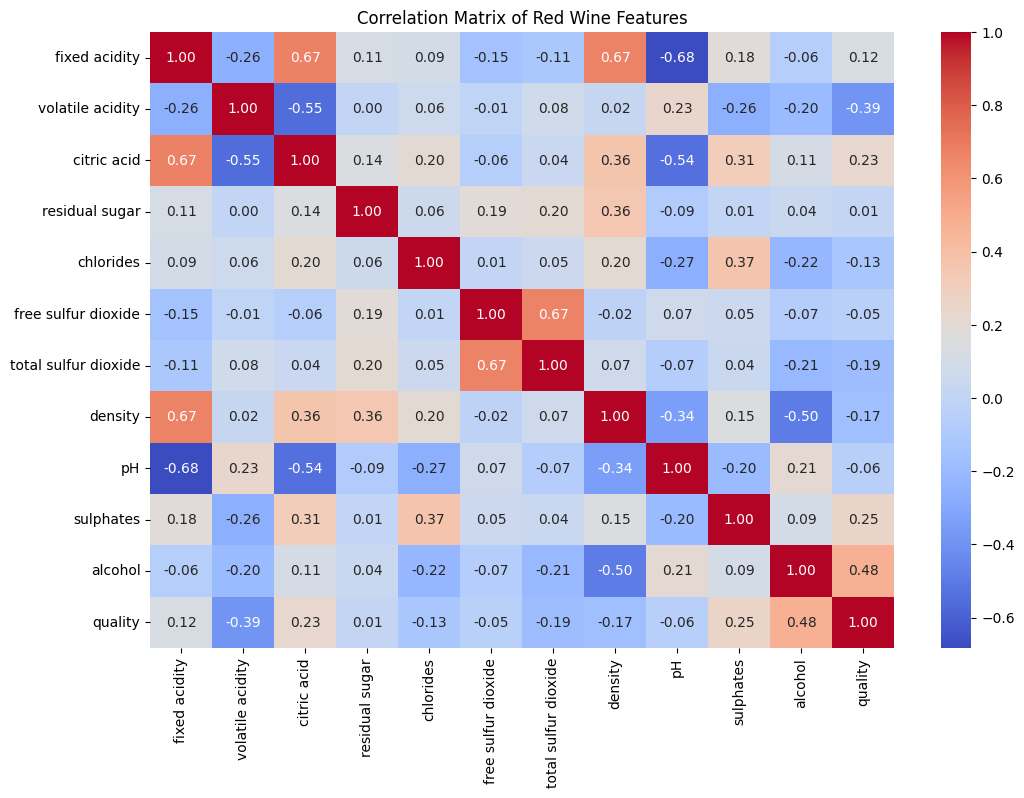

In [33]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    red_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Red Wine Features")
plt.show()

In [34]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

X_red = red_df.drop(columns=["quality"])
y_red = red_df["quality"]

X_train_red, X_test_red, y_train_red, y_test_red = train_test_split(
    X_red,
    y_red,
    test_size=0.2,
    random_state=42
)

red_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

red_model.fit(X_train_red, y_train_red)

print("Red wine model trained!")

Red wine model trained!


In [35]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

red_pred = red_model.predict(X_test_red)

print("Red Wine MAE:",
      round(mean_absolute_error(y_test_red, red_pred), 4))

print("Red Wine RMSE:",
      round(mean_squared_error(y_test_red, red_pred) ** 0.5, 4))

print("Red Wine R²:",
      round(r2_score(y_test_red, red_pred), 4))

Red Wine MAE: 0.4238
Red Wine RMSE: 0.5536
Red Wine R²: 0.5311


In [36]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 10, 15, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [0.7, 1.0]
}

In [37]:
rf_red = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

search_red = RandomizedSearchCV(
    estimator=rf_red,
    param_distributions=param_grid,
    n_iter=25,
    scoring="neg_mean_absolute_error",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search_red.fit(X_train_red, y_train_red)

print("Best parameters:", search_red.best_params_)
print("Best CV MAE:", round(-search_red.best_score_, 4))

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best parameters: {'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': 15}
Best CV MAE: 0.4312


In [38]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

best_red_model = search_red.best_estimator_

red_tuned_pred = best_red_model.predict(X_test_red)

print("Tuned Red Wine MAE:",
      round(mean_absolute_error(y_test_red, red_tuned_pred), 4))

print("Tuned Red Wine RMSE:",
      round(mean_squared_error(y_test_red, red_tuned_pred) ** 0.5, 4))

print("Tuned Red Wine R²:",
      round(r2_score(y_test_red, red_tuned_pred), 4))

Tuned Red Wine MAE: 0.4288
Tuned Red Wine RMSE: 0.558
Tuned Red Wine R²: 0.5236


In [39]:
red_comparison = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R²"],
    "Original RF": [
        mean_absolute_error(y_test_red, red_pred),
        mean_squared_error(y_test_red, red_pred) ** 0.5,
        r2_score(y_test_red, red_pred)
    ],
    "Tuned RF": [
        mean_absolute_error(y_test_red, red_tuned_pred),
        mean_squared_error(y_test_red, red_tuned_pred) ** 0.5,
        r2_score(y_test_red, red_tuned_pred)
    ]
})

red_comparison.round(4)

,Metric,Original RF,Tuned RF
0,MAE,0.4238,0.4288
1,RMSE,0.5536,0.5580
2,R²,0.5311,0.5236


In [40]:
comparison = pd.DataFrame({
    "Wine Type": ["White", "Red"],
    "MAE": [
        mean_absolute_error(y_test, y_pred),
        mean_absolute_error(y_test_red, red_pred)
    ],
    "RMSE": [
        mean_squared_error(y_test, y_pred) ** 0.5,
        mean_squared_error(y_test_red, red_pred) ** 0.5
    ],
    "R2": [
        r2_score(y_test, y_pred),
        r2_score(y_test_red, red_pred)
    ]
})

comparison.round(4)

,Wine Type,MAE,RMSE,R2
0,White,0.4167,0.5876,0.5542
1,Red,0.4238,0.5536,0.5311
